# Experiment No. 10 — End-to-End Data Analytics Project: Business Intelligence and Predictive Analytics using a Real-World Dataset

- **Name:** Abhigyan Dubey
- **Course & Branch:** B.TECH CSE
- **CUID:** CU24250059
- **SUBJECT:** Mastery in Data Analytics and Visualizations and Career Advancement
- **SEM & Section:** 5th SEM, "B"

**Aim:** To implement a complete data analytics workflow on a real-world dataset by performing data collection, preprocessing, exploratory data analysis, visualization, statistical analysis, predictive modeling, and presentation of actionable business insights.

**Dataset:** Titanic Survival Dataset, loaded via `seaborn.load_dataset('titanic')` — no download needed.

---

## Step 1: Select the dataset and define the problem

**Problem statement:** *Which passengers were most likely to survive, and can we predict survival from passenger details?*
This is a **classification** problem (survived = 1 / not survived = 0), the same kind of problem as customer churn or employee attrition prediction in business.

## Step 2: Collect data and preprocess it

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

sns.set_theme(style="whitegrid")

df = sns.load_dataset('titanic')
print("Original shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])

Original shape: (891, 15)

Missing values:
 age            177
embarked         2
deck           688
embark_town      2
dtype: int64


In [2]:
# Missing values
df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df = df.drop(columns=['deck'])            # too many missing values

# Duplicates
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# Outliers in fare (IQR method, capped not dropped)
Q1, Q3 = df['fare'].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
df['fare'] = df['fare'].clip(lower, upper)

# Categorical variables
df['sex'] = df['sex'].map({'male': 0, 'female': 1})
df = pd.get_dummies(df, columns=['embarked'], drop_first=True)

# Feature engineering
df['family_size'] = df['sibsp'] + df['parch'] + 1

print("Shape after preprocessing:", df.shape)
print("Remaining missing values (excluding embark_town):", df.drop(columns=['embark_town']).isnull().sum().sum())

Duplicate rows: 116
Shape after preprocessing: (775, 16)
Remaining missing values (excluding embark_town): 0


## Step 3: Exploratory Data Analysis (EDA)

In [3]:
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked_Q', 'embarked_S', 'family_size']

print(df[['age', 'fare', 'family_size']].describe().round(2))
print("\nOverall survival rate:", round(df['survived'].mean(), 3))
print("\nSurvival rate by sex (0 = male, 1 = female):\n", df.groupby('sex')['survived'].mean().round(2))
print("\nSurvival rate by class:\n", df.groupby('pclass')['survived'].mean().round(2))

          age    fare  family_size
count  775.00  775.00       775.00
mean    29.58   26.59         1.95
std     13.77   22.87         1.52
min      0.42    0.00         1.00
25%     21.00    8.05         1.00
50%     28.00   15.90         1.00
75%     36.00   34.20         2.00
max     80.00   73.42        11.00

Overall survival rate: 0.413

Survival rate by sex (0 = male, 1 = female):
 sex
0    0.22
1    0.74
Name: survived, dtype: float64

Survival rate by class:
 pclass
1    0.63
2    0.51
3    0.26
Name: survived, dtype: float64


## Step 4: Statistical analysis (correlation + hypothesis tests)

In [4]:
# Correlation with survival
corr = df[features + ['survived']].corr()['survived'].drop('survived').round(2)
print("Correlation with survived:\n", corr.sort_values())

# Chi-square test: is survival related to sex?   H0: sex and survival are independent
chi2, p_chi, _, _ = stats.chi2_contingency(pd.crosstab(df['sex'], df['survived']))
print("\nChi-square test (sex vs survived): p-value =", p_chi)

# t-test: is mean age different for survivors and non-survivors?   H0: means are equal
t, p_t = stats.ttest_ind(df[df['survived'] == 1]['age'],
                         df[df['survived'] == 0]['age'], equal_var=False)
print("t-test (age by survival): p-value =", round(p_t, 4))

Correlation with survived:
 pclass        -0.33
embarked_S    -0.13
age           -0.08
sibsp         -0.04
embarked_Q    -0.04
family_size    0.01
parch          0.07
fare           0.31
sex            0.52
Name: survived, dtype: float64

Chi-square test (sex vs survived): p-value = 2.422673602275232e-46
t-test (age by survival): p-value = 0.031


## Step 5: Visualizations (dashboard)

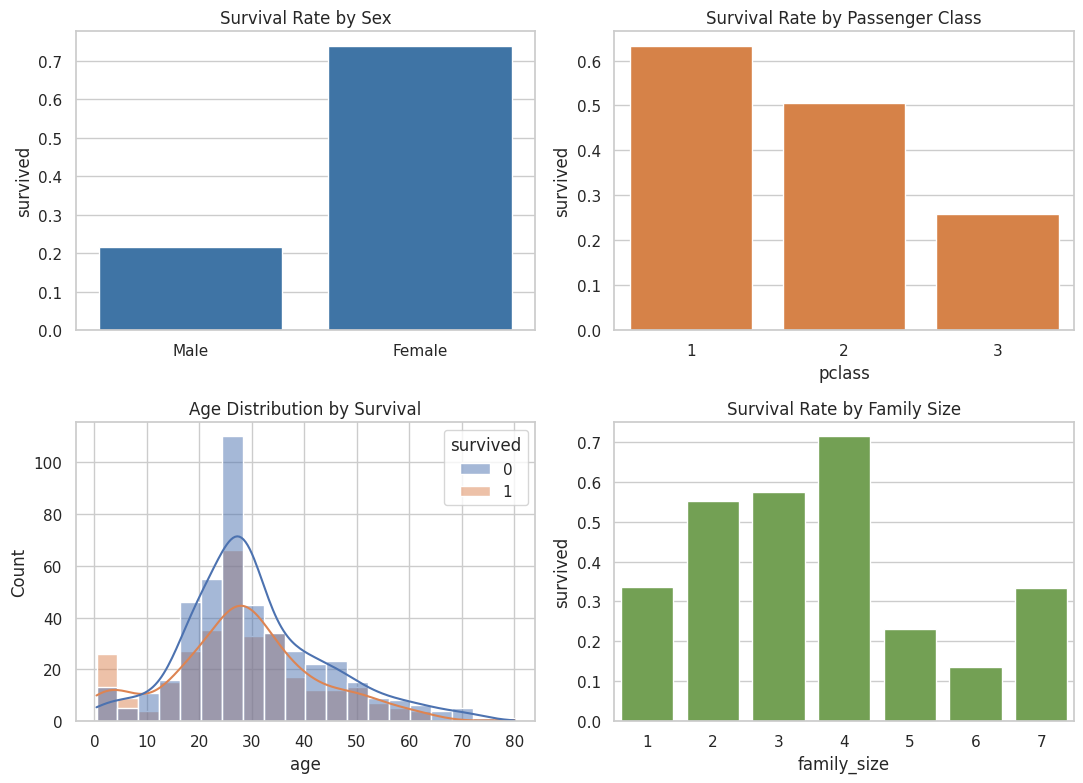

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

sns.barplot(data=df, x='sex', y='survived', errorbar=None, ax=axes[0, 0], color="#2E75B6")
axes[0, 0].set_title("Survival Rate by Sex")
axes[0, 0].set_xticks([0, 1]); axes[0, 0].set_xticklabels(['Male', 'Female'])
axes[0, 0].set_xlabel("")

sns.barplot(data=df, x='pclass', y='survived', errorbar=None, ax=axes[0, 1], color="#ED7D31")
axes[0, 1].set_title("Survival Rate by Passenger Class")

sns.histplot(data=df, x='age', hue='survived', bins=20, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Age Distribution by Survival")

fam = df[df['family_size'] <= 7]
sns.barplot(data=fam, x='family_size', y='survived', errorbar=None, ax=axes[1, 1], color="#70AD47")
axes[1, 1].set_title("Survival Rate by Family Size")

plt.tight_layout(); plt.show()

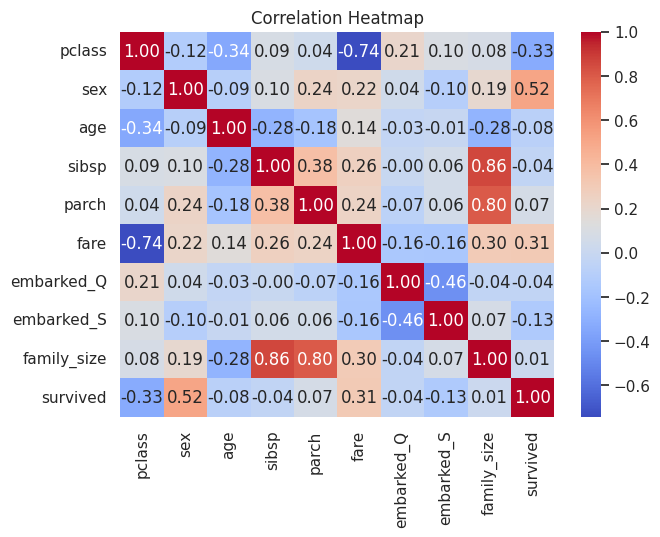

In [6]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[features + ['survived']].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

## Step 6: Build the machine learning model

A **Decision Tree** is used as the main model (easy to explain to business users) and **Logistic Regression** as a baseline for comparison.

In [7]:
X = df[features].astype(float)
y = df['survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training data:", X_train.shape, " Testing data:", X_test.shape)

log_model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
tree_model = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_train, y_train)

Training data: (620, 9)  Testing data: (155, 9)


## Step 7: Evaluate the models

In [8]:
results = []
for name, m in [("Logistic Regression", log_model), ("Decision Tree", tree_model)]:
    pred = m.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
    })
pd.DataFrame(results).set_index("Model").round(3)

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.761,0.714,0.703,0.709
Decision Tree,0.806,0.827,0.672,0.741


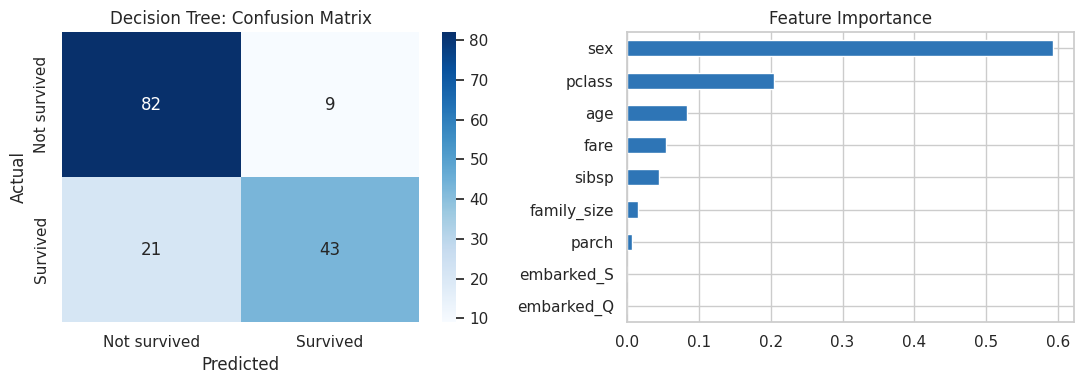

sex            0.592
pclass         0.204
age            0.083
fare           0.054
sibsp          0.044
family_size    0.015
parch          0.007
embarked_Q     0.000
embarked_S     0.000
dtype: float64


In [9]:
pred = tree_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap="Blues", ax=axes[0],
            xticklabels=['Not survived', 'Survived'], yticklabels=['Not survived', 'Survived'])
axes[0].set_title("Decision Tree: Confusion Matrix")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

imp = pd.Series(tree_model.feature_importances_, index=features).sort_values()
imp.plot(kind='barh', ax=axes[1], color="#2E75B6")
axes[1].set_title("Feature Importance")
plt.tight_layout(); plt.show()

print(imp.sort_values(ascending=False).round(3))

## Step 8: Interpretation and key insights

1. **Sex is the strongest factor:** 74% of women survived vs 22% of men. The chi-square test (p ≈ 2e-46) confirms this is not by chance, and the Decision Tree gives `sex` the highest importance (≈ 59%).
2. **Class matters:** survival was 63% (1st), 51% (2nd) and 26% (3rd). `pclass` (≈ 20% importance) and `fare` are strongly related to survival.
3. **Age has a small effect:** the t-test (p ≈ 0.031) shows survivors were slightly younger, but age adds little predictive power (≈ 8%).
4. **Family size:** passengers in groups of 2–4 survived most (≈ 55–71%); solo travellers ≈ 34%; very large families (5+) did worst.
5. **Model performance:** the Decision Tree reached **Accuracy ≈ 0.81, Precision ≈ 0.83, Recall ≈ 0.67, F1 ≈ 0.74**, better than the Logistic Regression baseline (Accuracy ≈ 0.76). It is good at being right when it predicts survival, but misses about a third of actual survivors (recall).
6. **Risk / limitation:** small dataset (775 rows after cleaning) and only one train/test split, so results are indicative.

### Recommendations (business-style takeaways)

- **Focus on high-risk groups** (men, 3rd class, large families) when planning safety/priority resources — in business terms, target the segments with the worst outcomes.
- **Use the key drivers** (`sex`, `pclass`, `age`, `fare`) as the main features in future models and dashboards.
- **Improve recall** (tune the model, try Random Forest) if missing positive cases is costly.

## Step 9: Project report and presentation

Methodology: *Problem → Data collection → Preprocessing → EDA → Statistical tests → Visualizations → Modeling → Evaluation → Insights → Recommendations*. This notebook serves as the project report; the same charts can be put into slides or a Tableau / Power BI dashboard.

## Step 10: Conclusion

The complete workflow shows how raw data becomes decisions: cleaning made the data reliable, EDA and statistics found the real drivers, the model turned them into predictions, and the evaluation metrics show how far the predictions can be trusted. Presenting this clearly helps management choose where to act.

## Questions

**Q1. What are the major stages involved in an end-to-end data analytics project?**

**Ans:** (1) Define the problem, (2) collect data, (3) clean and preprocess it, (4) exploratory data analysis, (5) statistical analysis, (6) visualization/dashboards, (7) build the model, (8) evaluate the model, (9) interpret results and give recommendations, and (10) present/report and deploy or monitor.

**Q2. Why is data preprocessing considered the foundation of successful analytics and machine learning?**

**Ans:** Real data has missing values, duplicates, outliers and inconsistent formats. Models and analysis built on such data give biased or unreliable results ("garbage in, garbage out"). Clean, well-structured data makes every later step accurate and trustworthy.

**Q3. How does Exploratory Data Analysis (EDA) contribute to model development?**

**Ans:** EDA reveals distributions, outliers, missing data and relationships between features and the target. This guides feature selection, transformation (e.g., skewed fare), encoding choices and the choice of algorithm. In our project it showed `sex` and `pclass` were the strongest drivers.

**Q4. What factors should be considered while selecting a machine learning algorithm for a business problem?**

**Ans:** Type of problem (classification, regression, clustering), size and quality of data, number and type of features, interpretability needed by stakeholders, accuracy required, training time and cost, and risk of overfitting. Example: a Decision Tree was chosen here because it is accurate enough and easy to explain.

**Q5. Why is model evaluation essential before deploying a predictive model?**

**Ans:** Evaluation on unseen test data shows how well the model will perform in real use and exposes overfitting or bias. Metrics (accuracy, precision, recall, F1, MAE, RMSE, R²) let us compare models and decide whether it is reliable enough to deploy, avoiding costly wrong decisions.

**Q6. Explain how Business Intelligence tools complement machine learning in data analytics projects.**

**Ans:** ML predicts and finds patterns; BI tools (Tableau, Power BI) present data, KPIs and predictions in interactive dashboards that non-technical users can explore. ML provides the intelligence, BI provides the communication and monitoring, so insights reach decision-makers.

**Q7. What challenges are commonly encountered while working with real-world datasets?**

**Ans:** Missing and inconsistent data, duplicates, outliers, imbalanced classes, very large volume, mixed data types, data privacy and security, biased or unrepresentative samples, and difficulty combining data from different sources.

**Q8. How can analytical insights be converted into actionable business recommendations?**

**Ans:** Link each finding to a business goal, quantify its impact, identify the affected segment, and propose a specific, measurable action with an owner and a way to track results. Example: "3rd-class passengers had the lowest survival (26%), so prioritise resources for that group."

**Q9. Why is effective presentation and data storytelling important in analytics projects?**

**Ans:** Stakeholders act on insights they understand. Clear visuals and a logical story (problem → analysis → findings → recommendations) make results convincing, avoid misinterpretation, and turn technical output into decisions.

**Q10. Suggest future improvements or advanced techniques that could enhance the accuracy and effectiveness of the developed analytics solution.**

**Ans:** Use cross-validation and hyperparameter tuning, try ensemble models (Random Forest, Gradient Boosting/XGBoost), engineer more features (e.g., title extracted from name), handle class imbalance, collect more data, and deploy the model with an interactive dashboard (Streamlit / Power BI) for continuous monitoring.